In [3]:
from google.colab import files
uploaded = files.upload()

Saving IT_Support_Tickets_Cleaned.csv to IT_Support_Tickets_Cleaned.csv


In [4]:
import pandas as pd

df = pd.read_csv('IT_Support_Tickets_Cleaned.csv')

print(df.shape)
df.head()

(1800, 9)


,ticket_id,created_at,priority,requester_dept,model_text,category,assignment_group,status,resolution_hours
0,INC100000,2026-04-01 05:26:00,P4,Legal,"dns issue hi, the intranet portal doesn't load...",Network,Network Operations,Resolved,41.7
1,INC100001,2026-04-01 09:43:00,P3,HR,"account creation dear support, please set up a...",Access,Identity & Access Management,Resolved,5.3
2,INC100002,2026-04-01 10:04:00,P3,Sales,"excel closes itself good morning, excel stops ...",Software,Application Support,Resolved,12.4
3,INC100003,2026-04-01 12:18:00,P4,Operations,quota exceeded i get a mailbox almost full war...,Email & Collaboration,Messaging & Collaboration,Resolved,8.2
4,INC100004,2026-04-01 15:12:00,P3,Marketing,"new hire setup hi it, a new team member joins ...",Access,Identity & Access Management,Resolved,4.5


In [6]:
# Input feature and target variable

X = df['model_text'].fillna('')
y = df['category']

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategories:")
print(y.value_counts())

Input shape: (1800,)
Target shape: (1800,)

Categories:
category
Access                   409
Network                  352
Software                 338
Hardware                 282
Email & Collaboration    258
Security                 107
Other                     54
Name: count, dtype: int64


In [7]:
from sklearn.model_selection import GroupShuffleSplit

# Split based on identical text groups
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=X)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1439
Testing records: 361


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2
)

# Fit on training data and transform it
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (1439, 3911)
Testing TF-IDF shape: (361, 3911)


In [9]:
# Get vocabulary features

feature_names = tfidf.get_feature_names_out()

print("Total vocabulary features:", len(feature_names))

print("\nFirst 30 features:")
print(feature_names[:30])

Total vocabulary features: 3911

First 30 features:
['0x80070005' '0x80070005 it' '0xc0000142' '0xc0000142 when' '10' '10 111'
 '10 113' '10 131' '10 143' '10 152' '10 157' '10 160' '10 167' '10 185'
 '10 195' '10 196' '10 237' '10 242' '10 250' '10 46' '10 55' '10 56'
 '10 63' '10 minutes' '10 times' '101' '106' '107' '111' '113']


In [10]:
# Convert first training record into a readable table

tfidf_df = pd.DataFrame(
    X_train_tfidf[0].toarray(),
    columns=feature_names
)

# Display only words with non-zero TF-IDF scores
display(
    tfidf_df.loc[:, (tfidf_df != 0).any(axis=0)].T
    .rename(columns={0: 'TF-IDF Score'})
    .sort_values('TF-IDF Score', ascending=False)
)

,TF-IDF Score
weekend this,0.267566
portal doesn,0.267566
doesn load,0.267566
doesn,0.236057
intranet portal,0.228259
the intranet,0.228259
dns issue,0.216208
work regards,0.216208
intranet,0.216208
dns,0.203134


In [11]:
print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training matrix: (1439, 3911)
Testing matrix: (361, 3911)
Training labels: (1439,)
Testing labels: (361,)


In [12]:
from sklearn.linear_model import LogisticRegression

# Initialize the model
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

In [13]:
# Train Logistic Regression using TF-IDF training data

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [14]:
# Predict categories for testing data

y_pred = model.predict(X_test_tfidf)

print("Predictions:")
print(y_pred[:10])

Predictions:
['Software' 'Network' 'Email & Collaboration' 'Software' 'Other'
 'Security' 'Network' 'Network' 'Email & Collaboration' 'Network']


In [15]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 88.92 %


In [16]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

                       precision    recall  f1-score   support

               Access       0.91      0.91      0.91        67
Email & Collaboration       0.95      0.78      0.86        54
             Hardware       0.89      0.91      0.90        55
              Network       0.86      0.91      0.88        78
                Other       1.00      1.00      1.00        13
             Security       0.71      0.83      0.77        24
             Software       0.91      0.91      0.91        70

             accuracy                           0.89       361
            macro avg       0.89      0.89      0.89       361
         weighted avg       0.89      0.89      0.89       361



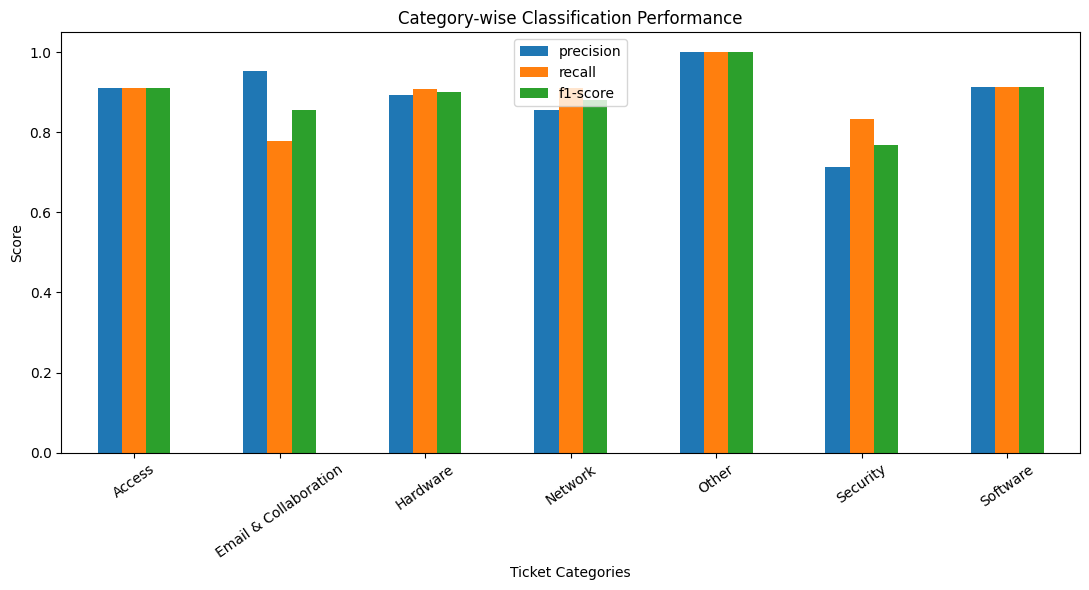

In [23]:
#Category-wise prediction performance
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

category_metrics = report_df.loc[
    list(model.classes_),
    ['precision', 'recall', 'f1-score']
]

category_metrics.plot(
    kind='bar',
    figsize=(11,6)
)

plt.title('Category-wise Classification Performance')
plt.xlabel('Ticket Categories')
plt.ylabel('Score')
plt.xticks(rotation=35)
plt.legend()
plt.tight_layout()
plt.show()

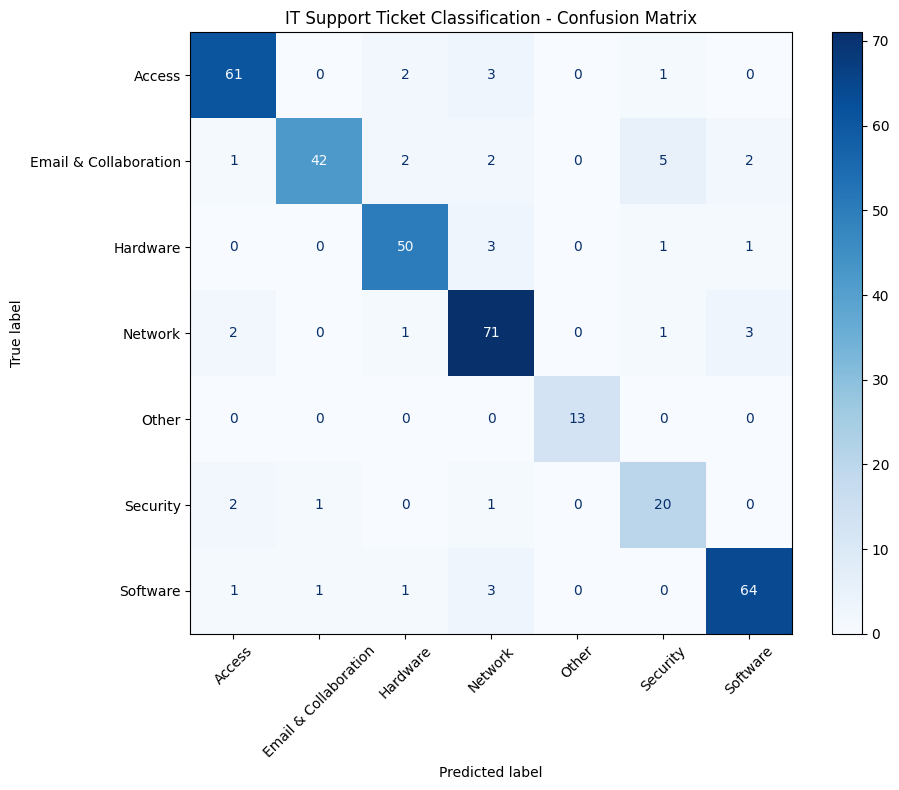

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title("IT Support Ticket Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
# Get prediction probabilities

y_prob = model.predict_proba(X_test_tfidf)

# Get highest probability for each prediction
confidence = y_prob.max(axis=1)

# Display predictions
results = pd.DataFrame({
    'Actual Category': y_test.values,
    'Predicted Category': y_pred,
    'Confidence': confidence
})

display(results.head(10))

,Actual Category,Predicted Category,Confidence
0,Software,Software,0.519482
1,Access,Network,0.340844
2,Email & Collaboration,Email & Collaboration,0.434740
3,Email & Collaboration,Software,0.249904
4,Other,Other,0.805897
5,Security,Security,0.412947
6,Network,Network,0.645139
7,Access,Network,0.345965
8,Email & Collaboration,Email & Collaboration,0.800383
9,Network,Network,0.529323


In [19]:
threshold = 0.70

results['Routing Status'] = results['Confidence'].apply(
    lambda x: 'Auto Route' if x >= threshold
    else 'Manual Review'
)

display(results.head(15))

,Actual Category,Predicted Category,Confidence,Routing Status
0,Software,Software,0.519482,Manual Review
1,Access,Network,0.340844,Manual Review
2,Email & Collaboration,Email & Collaboration,0.434740,Manual Review
3,Email & Collaboration,Software,0.249904,Manual Review
4,Other,Other,0.805897,Auto Route
5,Security,Security,0.412947,Manual Review
6,Network,Network,0.645139,Manual Review
7,Access,Network,0.345965,Manual Review
8,Email & Collaboration,Email & Collaboration,0.800383,Auto Route
9,Network,Network,0.529323,Manual Review


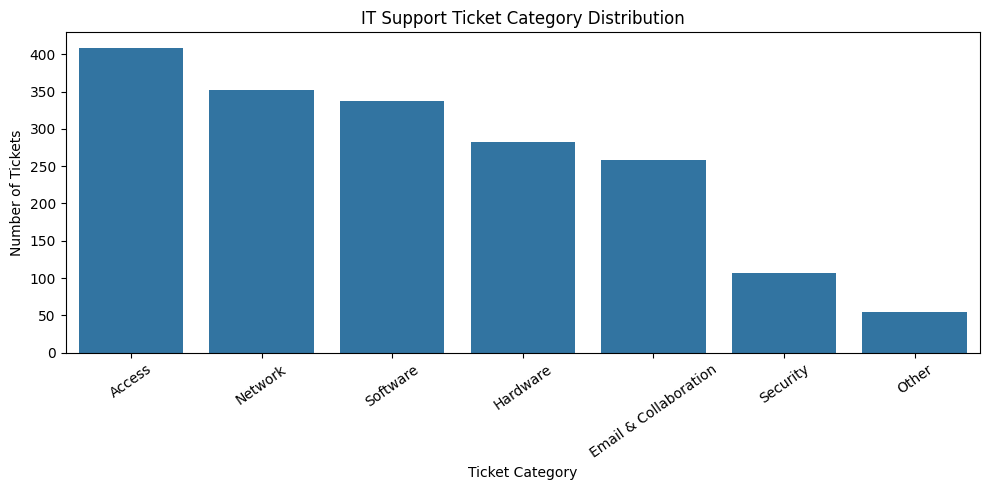

In [21]:
#Category distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x='category',
    order=df['category'].value_counts().index
)

plt.title('IT Support Ticket Category Distribution')
plt.xlabel('Ticket Category')
plt.ylabel('Number of Tickets')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()
